In [16]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.spatial import distance_matrix
from scipy.spatial import distance
from scipy.optimize import minimize
from scipy.optimize import basinhopping
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
import math
import shutil
import time
from numba import jit
import os
import statistics
from scipy.interpolate import interp1d
from scipy.interpolate import CubicSpline



In [17]:
##############################################
# To Create your platelet, you can vary the 
# dimensions below. The rest of the data initialization
# section of the code does not need to be changed.
##############################################

flat_radius = 5.19  #flat plate radius

hex_radius = 5.19   #hexagon radius
n_rings = 3
z_dist = 5.44  #z distance between plateletes for 2 layer platelet system


theta = 63 *np.pi/180   #theta of double layer platelet system, in rad


x_dist = z_dist/np.tan(theta) #x distance shift of bottom layer based on theta

y_dist=x_dist




In [42]:
def Plate(radius,w_max,h_max):
  w = radius
  h = np.sqrt(3)*radius/2

  coordinates = []
  for y in np.arange(0, h_max, h):
    f=0
    for x in np.arange(0, w_max, w):
      coordinates.append((x, y))
      f+=1
  coordinates = np.array(coordinates)
  
  i=0
  while i < (len(coordinates[:,0])+f*2):
    coordinates[i:i+f,0] += radius/2
    i += f*2
  return coordinates

###################


def hexa(n_rings,radius):
    #width and height of the hexagon
    w = radius*2/np.sqrt(3)
    h = radius
    N = int(n_rings/2)

    #generate empty arrays
    central_x = []
    central_y = []
    edge_x = []
    edge_y = []

    if (n_rings%2==1):
        print("n_rings must be even number")
    else:
        #top edge atom layer
        edge_x.append(0)
        edge_y.append(0)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #first half of hexagon
        for i in range(N):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0])
            central_y.append(edge_y[0]-h)
            for j in range(N+i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]-0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])

        #second half of hexagon
        for i in range(N-1):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N+(N-i)-1):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0]-h)
            for j in range(N+(N-i)-2):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]+0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N +(N-i)-3):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])
        central_x.append(edge_x[0]+0.75*w)
        central_y.append(edge_y[0]-0.5*h)
        for j in range(N):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        central_x.append(edge_x[0]+1.5*w)
        central_y.append(edge_y[0]-h)
        for j in range(N-1):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        edge_x.append(edge_x[0]+0.75*w)
        edge_y.append(edge_y[0]-1.5*h)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #center of mass back to 0
        edge_x -= np.average(edge_x)
        edge_y -= np.average(edge_y)
        central_x -= np.average(central_x)
        central_y -= np.average(central_y)

        #NEW - MERGE EDGE AND CENTRAL
        central_x = np.concatenate((central_x,edge_x))
        central_y = np.concatenate((central_y,edge_y))

        #NEW - EDGE ATOMS
        edge_x = []
        edge_y = []

        edge_x.append(n_rings*0.75*w+0.5*w)
        edge_y.append(0)

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)

        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]-1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)

    return central_x,central_y,edge_x,edge_y


def angle(xyz,axis,rotation_angle): #rotates platelet along an axis and at an angle (in rad)
    #INITIAL ATOMS
    atoms_initial = np.array([xyz[:,0],xyz[:,1],xyz[:,2]]).T
    
    #MAKE THE ROTATION MATRIX
    axis = np.asarray(axis)
    axis = axis / math.sqrt(np.dot(axis, axis))
    a = math.cos(rotation_angle / 2.0)
    b, c, d = -axis * math.sin(rotation_angle / 2.0)
    aa, bb, cc, dd = a * a, b * b, c * c, d * d
    bc, ad, ac, ab, bd, cd = b * c, a * d, a * c, a * b, b * d, c * d
    
    rotation_matrix = np.array([[aa + bb - cc - dd, 2 * (bc + ad), 2 * (bd - ac)],
                     [2 * (bc - ad), aa + cc - bb - dd, 2 * (cd + ab)],
                     [2 * (bd + ac), 2 * (cd - ab), aa + dd - bb - cc]])
    
    #  apply rotation matrix to our points
    atoms_rotated = np.dot(atoms_initial, rotation_matrix)
    
    return atoms_rotated

Total number of atoms:  25
Long diameter: 23.972 A: 


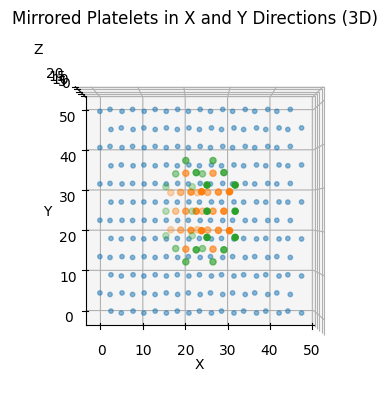

In [43]:

y,x ,yy, xx = hexa(2,hex_radius) 


#print total number of atoms
print("Total number of atoms: ",(len(x)+len(xx)))
print("Long diameter: %.3f A: " %(max(yy)-min(yy)))

z = np.zeros(len(x))
zz = np.zeros(len(xx))

#put x,y,z data into one array
CentralPlatelet = np.stack((x,y,z),axis=-1)
EdgePlatelet = np.stack((xx,yy,zz),axis=-1)

#make two platelets
CentralPlatelet2=CentralPlatelet.copy()
CentralPlatelet2[:,2]=CentralPlatelet[:,2]+z_dist
CentralPlatelet2[:,0]=CentralPlatelet[:,0]-x_dist

EdgePlatelet2=EdgePlatelet.copy()
EdgePlatelet2[:,2]=EdgePlatelet[:,2]+z_dist
EdgePlatelet2[:,0]=EdgePlatelet[:,0]-x_dist

#save into one array
CentralPlate = np.vstack((CentralPlatelet ,CentralPlatelet2))
EdgePlate = np.vstack((EdgePlatelet ,EdgePlatelet2))


coord = Plate(flat_radius,41.53,53) 

x_central = coord[:, 0]
y_central = coord[:, 1]
z_central = np.zeros(len(x_central))


Flat_central = np.stack((x_central, y_central, z_central), axis=-1)
Flat2_central = Flat_central.copy()
Flat2_central[:, 2] += z_dist
Flat2_central[:, 0] += x_dist




FlatPlate = np.vstack((Flat_central, Flat2_central))
FlatPlate[:,2] -= z_dist/2



CentralPlate = angle(CentralPlate,np.array([0,1,0]), theta)
EdgePlate = angle(EdgePlate,np.array([0,1,0]),theta)

# Lateral translation used to reproduce the position of the rotated
# hexagonal platelet relative to the periodic sheet in the atomistic
# reference configuration.
CentralPlate[:,0] = CentralPlate[:,0] + 10.817876120027421 + 23.355 - 7.7651487536619594
EdgePlate[:,0] = EdgePlate[:,0] + 10.817876120027421 + 23.355 - 7.7651487536619594

CentralPlate[:,1] = CentralPlate[:,1] + 24.72
EdgePlate[:,1] = EdgePlate[:,1] + 24.72


fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(FlatPlate[:, 0], FlatPlate[:, 1], FlatPlate[:, 2] , s=10, alpha=0.5)
ax.scatter(CentralPlate[:,0],CentralPlate[:,1],CentralPlate[:,2]+10,label="Central Atoms")
ax.scatter(EdgePlate[:,0],EdgePlate[:,1],EdgePlate[:,2]+10,label="Edge Atoms")
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Mirrored Platelets in X and Y Directions (3D)')
ax.view_init(elev=90, azim=270)

plt.show()



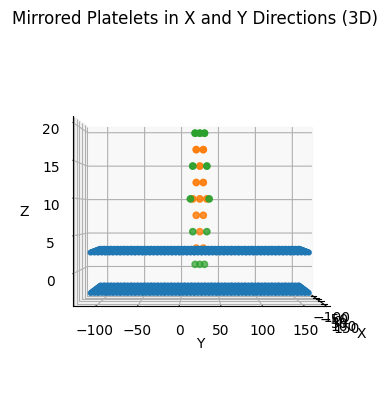

In [41]:
# Creating periodic sheet
x_offsets = [-2 * 46.72, -1 * 46.72, 0, 1 * 46.72, 2 * 46.72]  
y_offsets = [-2 * 53.94, -1 * 53.94, 0, 1 * 53.94, 2 * 53.94]  



FlatPlate_1 = []
FlatPlate_2 = []

for x in x_offsets:
    for y in y_offsets:
        displacement = np.array([x, y, 0])  # Displacement in x and y directions
        FlatPlate_1.append(Flat_central + displacement)
        FlatPlate_2.append(Flat2_central + displacement)

# Convert lists to numpy arrays
FlatPlate_1 = np.vstack(FlatPlate_1)
FlatPlate_2 = np.vstack(FlatPlate_2)


FlatPlate_P = np.vstack((FlatPlate_1, FlatPlate_2))
FlatPlate_P[:,2] -= z_dist/2


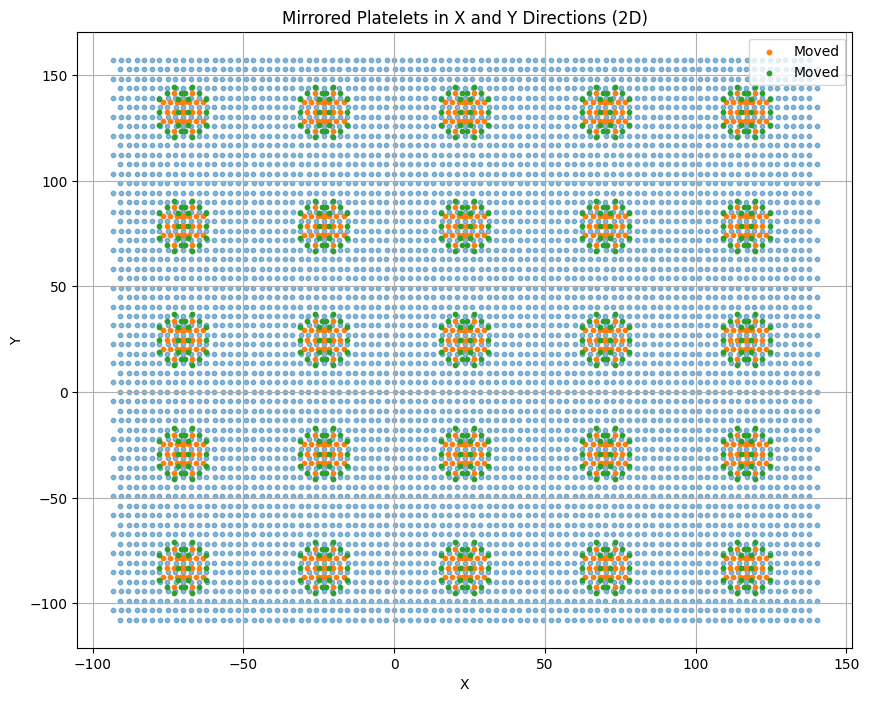

In [44]:
#Crearting periodic hexagons and plotting togheder in a way that match with my atomistic simulations

x_H = [-2 * 41.52, -1 * 41.52, 0, 1 * 41.52, 2 * 41.52]  
y_H = [-2 * 44.95, -1 * 44.95, 0, 1 * 44.95, 2 * 44.95]  



Edge_1 = []
Center_1 = []

for x in x_offsets:
    for y in y_offsets:
        displacement = np.array([x, y, 0])  # Displacement in x and y directions
        Edge_1.append(EdgePlate + displacement)
        Center_1.append(CentralPlate + displacement)

# Convert lists to numpy arrays
Edge_1_whole = np.vstack(Edge_1)
Center_1_whole = np.vstack(Center_1)

Edge_2_whole = np.vstack(Edge_1)
Center_2_whole = np.vstack(Center_1)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(FlatPlate_P[:, 0], FlatPlate_P[:, 1] , s=10, alpha=0.5)
ax.scatter(Center_1_whole[:,0],Center_1_whole[:,1] , s=10 ,label="Moved")
ax.scatter(Edge_1_whole[:,0],Edge_1_whole[:,1], s=10 , label="Moved")
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Mirrored Platelets in X and Y Directions (2D)')
ax.legend()
plt.grid()
plt.show()




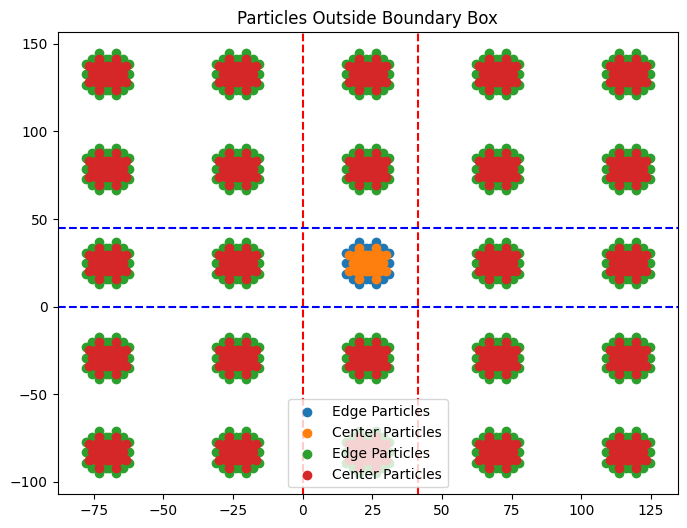

In [45]:
# separating the main hexagon and images to prepare them for the distance calculations 
# (I could have exclude them in the previous cell)

############## This is for pairwise distances between original hexagon and periodic sheet



# Boundary definitions
x_min_1 = 0
x_max_1 = 41.52  
y_min_1 = 0
y_max_1 = 44.95

# Filter for MAIN REGION (points INSIDE boundaries)
mask_1_ed = (
    (Edge_1_whole[:, 0] >= x_min_1) & (Edge_1_whole[:, 0] <= x_max_1) & 
    (Edge_1_whole[:, 1] >= y_min_1) & (Edge_1_whole[:, 1] <= y_max_1)
)

Edge_filtered_main = Edge_1_whole[mask_1_ed]

mask_1_cen = (
    (Center_1_whole[:, 0] >= x_min_1) & (Center_1_whole[:, 0] <= x_max_1) & 
    (Center_1_whole[:, 1] >= y_min_1) & (Center_1_whole[:, 1] <= y_max_1)
)

Center_filtered_main = Center_1_whole[mask_1_cen]

# Filter for EXTERNAL REGION (points OUTSIDE boundaries)
mask_1_ed_ex = (
    (Edge_2_whole[:, 0] < x_min_1) | (Edge_2_whole[:, 0] > x_max_1) | 
    (Edge_2_whole[:, 1] < y_min_1) | (Edge_2_whole[:, 1] > y_max_1))


mask_1_cen_ex = (
    (Center_2_whole[:, 0] < x_min_1) | (Center_2_whole[:, 0] > x_max_1) |
    (Center_2_whole[:, 1] < y_min_1) | (Center_2_whole[:, 1] > y_max_1))


Edge_filtered_ex = Edge_2_whole[mask_1_ed_ex]
Center_filtered_ex = Center_2_whole[mask_1_cen_ex]


plt.figure(figsize=(8,6))
plt.scatter(Edge_filtered_main[:,0], Edge_filtered_main[:,1], label='Edge Particles')
plt.scatter(Center_filtered_main[:,0], Center_filtered_main[:,1], label='Center Particles')
plt.axvline(x_min_1, color='r', linestyle='--')
plt.axvline(x_max_1, color='r', linestyle='--')
plt.axhline(y_min_1, color='b', linestyle='--')
plt.axhline(y_max_1, color='b', linestyle='--')
plt.scatter(Edge_filtered_ex[:,0], Edge_filtered_ex[:,1], label='Edge Particles')
plt.scatter(Center_filtered_ex[:,0], Center_filtered_ex[:,1], label='Center Particles')

plt.legend()
plt.title('Particles Outside Boundary Box')
plt.show()




In [47]:
# Creating a sheet with the same size as atomistic simulation box (This is used for the distance calculations)



coord_org = Plate(flat_radius,42,53) #  Original Platelet
print(max(coord_org[:,0]))
x_central_org = coord_org[:, 0]
y_central_org = coord_org[:, 1]
z_central_org = np.zeros(len(x_central_org))


Flat_central_org = np.stack((x_central_org, y_central_org, z_central_org), axis=-1)
Flat2_central_org = Flat_central_org.copy()
Flat2_central_org[:, 2] += z_dist
Flat2_central_org[:, 0] += x_dist


Flat2_central_org[:,2] -= z_dist/2
Flat_central_org[:,2] -= z_dist/2


FlatPlate_main = np.vstack((Flat_central_org, Flat2_central_org))

#############

x_min_1 = 0
x_max_1 = 41.52  
y_min_1 = 0
y_max_1 = 47

# Filter for Layer1 (points INSIDE boundaries)
mask_1_F1 = (
    (Flat_central_org[:, 0] >= x_min_1) & (Flat_central_org[:, 0] <= x_max_1) & 
    (Flat_central_org[:, 1] >= y_min_1) & (Flat_central_org[:, 1] <= y_max_1)
)

F1_filtered_main = Flat_central_org[mask_1_F1]


# Filter for Layer2 (points INSIDE boundaries)

x_min_1 = 2.6
x_max_1 = 46.71  
y_min_1 = 0
y_max_1 = 47

# Filter for Layer1 (points INSIDE boundaries)
mask_2_F2 = (
    (Flat2_central_org[:, 0] >= x_min_1) & (Flat2_central_org[:, 0] <= x_max_1) & 
    (Flat2_central_org[:, 1] >= y_min_1) & (Flat2_central_org[:, 1] <= y_max_1)
)

F2_filtered_main = Flat2_central_org[mask_2_F2]


###########

FlatPlate_main_Filtered = np.vstack((F1_filtered_main, F2_filtered_main))



44.115


In [ ]:
from pathlib import Path

DATA_DIR = Path("../data/testing/face_to_edge_63deg")


# ------------------------------------------------------------------
# PMF data
# ------------------------------------------------------------------

d_spacing = np.array([25.5489, 25.3795, 25.2964, 24.9639, 24.8199, 24.6078, 24.4191, 24.167, 24.0367, 23.8304, 23.6165, 23.4769, 23.3356, 23.0784, 22.964, 22.7202, 22.5436, 22.4243, 22.0728, 22.0094, 21.6594, 
                 21.6353, 21.5294, 21.0718, 20.9952, 20.7274, 20.5226, 20.3476, 20.1668, 19.9621, 19.7875, 19.6039, 19.3833, 19.3116, 19.0373, 18.8159, 18.7871, 18.4983, 18.2591, 18.059, 18.0452, 17.7744, 17.5934, 17.4272, 17.1134, 17.0289, 
                 16.7566, 16.7336, 16.4537, 16.3285, 16.164, 15.9544, 15.7613, 15.6869, 15.6192])
a_energy=np.array([0.0, -0.20270742585907275, -0.36918877226283414, -2.078498750460538, -2.214889752152339, -1.032860849406532, -0.9770597174608597, -1.7813618911681195, -1.653600245627321, -1.8952715573988608, -1.9226641709624326, -1.6875303637098693, -2.2486560292850295,
                 -3.7933352734671195, -4.06508649733626, -3.181749952344098, -2.815635684775228, -3.2254334666230267, -3.4592723029792642, -3.40218228184419, -3.7182436838607735, -3.7584835075526, -3.913446887681116, -3.6610258700459024, -3.316843203030365, -2.192827337958682, 
                 -1.8169245583289078, -1.567788267683321, -1.9042631745188192, -2.2429594736310587, -2.1400879449105035, -2.0804479152287745, -1.8887160835556165, -1.4775378171754054, 0.03184431967269647, 1.1964491943717557, 1.2894600585645597, 1.4591279850450107, 1.5502439021612142,
                 1.4802113319441779, 1.5444126105184173, 2.7013120599720026, 3.5041506065645285, 4.617482320738152, 7.813984618755109, 8.6328783972163, 11.751860041385816, 12.133965226392238, 16.69954882342474, 19.53532435251821, 25.137306090477306, 35.73209668238645, 47.80670727278394, 
                 52.62063153428732, 57.365745251266425])

f_Stack = np.stack((d_spacing, a_energy), axis = -1)
sorted_indices = np.argsort(f_Stack[:, 0])
f_Stack = f_Stack[sorted_indices]
d_spacing = f_Stack[:, 0]
z_S = f_Stack[:, 0]



# ------------------------------------------------------------------
# Center-center pairwise distances
# ------------------------------------------------------------------

# 1. Distances between the original hexagon and periodic sheet
# 2. Distances between the original sheet and periodic hexagon images

cen_dis = {}

for i, spacing in enumerate(z_S):

    # Original hexagon centers -> periodic sheet
    Hex_cen = Center_filtered_main.copy()
    Hex_cen[:, 2] += spacing

    dist_matrix = distance.cdist(Hex_cen, FlatPlate_P)
    final_distances = dist_matrix[dist_matrix <= 25]

    # Original sheet -> periodic hexagon centers
    Hex_cen_ex = Center_filtered_ex.copy()
    Hex_cen_ex[:, 2] += spacing

    dist_matrix_2 = distance.cdist(
        FlatPlate_main_Filtered,
        Hex_cen_ex
    )

    final_distances_2 = dist_matrix_2[
        dist_matrix_2 <= 25
    ]

    # Combine distances
    combined_distances = np.concatenate(
        (final_distances, final_distances_2)
    )

    cen_dis[round(spacing, 5)] = combined_distances

    print(
        f"Iteration {i}: d-spacing = {spacing}, "
        f"Kept {len(combined_distances)} distances"
    )


# Save CC distances
output_file_npy = DATA_DIR / "PairDis_Angle_1_CC.npy"
np.save(output_file_npy, cen_dis, allow_pickle=True)


# ------------------------------------------------------------------
# Edge-center pairwise distances
# ------------------------------------------------------------------

ed_cen_dis = {}

for i, spacing in enumerate(z_S):

    # Original hexagon edge sites -> periodic sheet
    Hex_ed = Edge_filtered_main.copy()
    Hex_ed[:, 2] += spacing

    dist_matrix = distance.cdist(Hex_ed, FlatPlate_P)
    final_distances = dist_matrix[dist_matrix <= 25]

    # Original sheet -> periodic hexagon edge sites
    Hex_ed_ex = Edge_filtered_ex.copy()
    Hex_ed_ex[:, 2] += spacing

    dist_matrix_2 = distance.cdist(
        FlatPlate_main_Filtered,
        Hex_ed_ex
    )

    final_distances_2 = dist_matrix_2[
        dist_matrix_2 <= 25
    ]

    # Combine distances
    combined_distances = np.concatenate(
        (final_distances, final_distances_2)
    )

    ed_cen_dis[round(spacing, 5)] = combined_distances

    print(
        f"Iteration {i}: d-spacing = {spacing}, "
        f"Kept {len(combined_distances)} distances"
    )


# Save EC distances
output_file_npy = DATA_DIR / "PairDis_Angle_1_EC.npy"
np.save(output_file_npy, ed_cen_dis, allow_pickle=True)


# ------------------------------------------------------------------
# Verify saved files
# ------------------------------------------------------------------

d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}

for output_file_npy in [
    DATA_DIR / "PairDis_Angle_1_CC.npy",
    DATA_DIR / "PairDis_Angle_1_EC.npy",
]:

    loaded_data = np.load(
        output_file_npy,
        allow_pickle=True
    ).item()

    d_spacing_npy = {
        round(x, 5) for x in loaded_data.keys()
    }

    missing_in_out = d_spacing_npy - d_spacing_out
    missing_in_npy = d_spacing_out - d_spacing_npy

    print(f"\nChecking {output_file_npy.name}")
    print(f"Missing in .out file: {missing_in_out}")
    print(f"Missing in .npy file: {missing_in_npy}")

    for key in list(loaded_data.keys())[:5]:
        print(
            f"d-spacing: {key}, "
            f"Number of distances: {len(loaded_data[key])}"
        )

    
    